# 02 — Baseline Modeling: Predicta

## Objective

Build a first machine-learning model to estimate the Remaining Useful Life (RUL) of an engine using sensor measurements and operating settings.

## Dataset

NASA C-MAPSS Turbofan Engine Degradation Simulation Dataset — FD001.

## Approach

1. Load and prepare the dataset.
2. Split engines into training and validation sets.
3. Train a baseline regression model.
4. Evaluate predictions using MAE, RMSE, and R².
5. Document limitations and potential improvements.

## Experimental principle

All observations from a given engine must remain in the same split to reduce information leakage between training and validation data.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
PROJECT_ROOT = Path.cwd()

# Handle cases where PyCharm starts in the notebooks directory
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "train_FD001.txt"

columns = (
    ["unit", "cycle", "setting_1", "setting_2", "setting_3"]
    + [f"sensor_{i}" for i in range(1, 22)]
)

train = pd.read_csv(
    DATA_PATH,
    sep=r"\s+",
    header=None,
    names=columns
)

last_cycle = train.groupby("unit")["cycle"].max()
train["RUL"] = train["unit"].map(last_cycle) - train["cycle"]

print("Dataset shape:", train.shape)
print("Number of engines:", train["unit"].nunique())
print("RUL range:", train["RUL"].min(), "to", train["RUL"].max())

train.head()

Dataset shape: (20631, 27)
Number of engines: 100
RUL range: 0 to 361


,unit,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187


In [4]:
engine_ids = train["unit"].unique()

train_units, val_units = train_test_split(
    engine_ids,
    test_size=0.2,
    random_state=42
)

train_df = train[train["unit"].isin(train_units)].copy()
val_df = train[train["unit"].isin(val_units)].copy()

print("Training engines:", train_df["unit"].nunique())
print("Validation engines:", val_df["unit"].nunique())
print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))

Training engines: 80
Validation engines: 20
Training rows: 16561
Validation rows: 4070


In [5]:
feature_cols = [
    col for col in train.columns
    if col.startswith("sensor_") or col.startswith("setting_")
]

X_train = train_df[feature_cols]
y_train = train_df["RUL"]

X_val = val_df[feature_cols]
y_val = val_df["RUL"]

print("Number of features:", len(feature_cols))
print("Training input shape:", X_train.shape)
print("Validation input shape:", X_val.shape)

Number of features: 24
Training input shape: (16561, 24)
Validation input shape: (4070, 24)


In [6]:
from sklearn.linear_model import Ridge

# Create the model
baseline_model = Ridge(alpha=1.0)

# Train it
baseline_model.fit(X_train, y_train)

print("Baseline model trained successfully!")

Baseline model trained successfully!


In [7]:
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predict RUL for validation engines
y_pred = baseline_model.predict(X_val)

# Calculate evaluation metrics
mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))
r2 = r2_score(y_val, y_pred)

print(f"MAE:  {mae:.2f} cycles")
print(f"RMSE: {rmse:.2f} cycles")
print(f"R²:   {r2:.3f}")

MAE:  30.12 cycles
RMSE: 38.14 cycles
R²:   0.662


## Baseline Results — Ridge Regression

The initial Ridge Regression model was trained using 24 sensor and operating-setting features. Evaluation was performed on a validation set containing 20 engines that were excluded from training.

| Metric |       Result |
| ------ | -----------: |
| MAE    | 30.12 cycles |
| RMSE   | 38.14 cycles |
| R²     |        0.662 |

The model achieved an MAE of 30.12 cycles and an R² of 0.662 on the validation set. These results establish an initial reference point for subsequent experiments.

The RMSE was higher than the MAE, indicating that larger prediction errors contribute to the overall error. Further experiments will compare this baseline with simpler benchmarks and nonlinear models.

**Limitations:** This is a single engine-level validation split. The results may vary with a different split, and the model's performance should not be interpreted as evidence of deployment readiness.


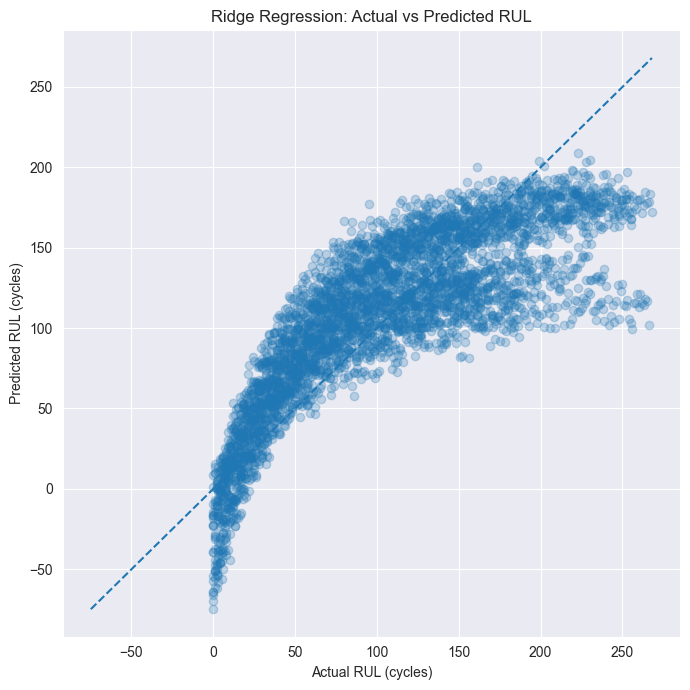

In [8]:
plt.figure(figsize=(7, 7))

plt.scatter(y_val, y_pred, alpha=0.25)

# Perfect predictions would lie on this diagonal
min_val = min(y_val.min(), y_pred.min())
max_val = max(y_val.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual RUL (cycles)")
plt.ylabel("Predicted RUL (cycles)")
plt.title("Ridge Regression: Actual vs Predicted RUL")
plt.tight_layout()
plt.show()

### Actual vs. Predicted RUL

The actual-versus-predicted plot shows a general positive relationship between actual and predicted RUL. However, predictions are compressed toward an intermediate range: the model tends to overestimate lower RUL values and underestimate higher RUL values.

The curved pattern suggests that a linear model may not fully capture the relationship between sensor measurements and RUL. This motivates testing a nonlinear regression model in a subsequent experiment.

These observations are based on visual inspection and should be confirmed with additional evaluation.


In [9]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions on the validation set
rf_pred = rf_model.predict(X_val)

# Evaluate the model
rf_mae = mean_absolute_error(y_val, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_val, rf_pred))
rf_r2 = r2_score(y_val, rf_pred)

# Display the results
print("Random Forest Results")
print("---------------------")
print(f"MAE:  {rf_mae:.2f} cycles")
print(f"RMSE: {rf_rmse:.2f} cycles")
print(f"R²:   {rf_r2:.3f}")

Random Forest Results
---------------------
MAE:  25.88 cycles
RMSE: 35.41 cycles
R²:   0.709


  feature  importance
sensor_11    0.442563
 sensor_9    0.127274
 sensor_4    0.077690
sensor_12    0.046156
sensor_14    0.040353
 sensor_7    0.037054
sensor_15    0.032272
sensor_21    0.031228
 sensor_3    0.028560
 sensor_2    0.027152
sensor_20    0.024147
setting_1    0.022823
 sensor_8    0.019997
sensor_13    0.019996
setting_2    0.013957


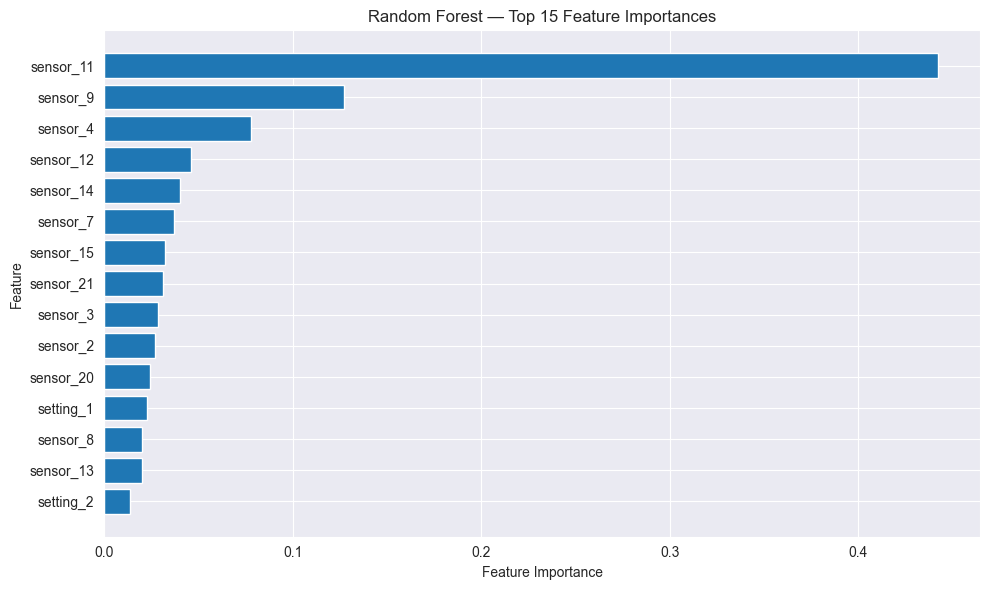

In [10]:

import pandas as pd
import matplotlib.pyplot as plt

# Get feature importances
importance_df = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf_model.feature_importances_
})

# Sort from most to least important
importance_df = importance_df.sort_values(
    by="importance",
    ascending=False
)

# Display the 15 most important features
print(importance_df.head(15).to_string(index=False))

# Plot feature importances
top_features = importance_df.head(15).sort_values(
    by="importance"
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_features["feature"],
    top_features["importance"]
)
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest — Top 15 Feature Importances")
plt.tight_layout()
plt.show()

### Random Forest Baseline

A Random Forest regressor was trained to predict the remaining useful life (RUL) of turbofan engines using sensor measurements and operating settings. The model was evaluated using the same engine-level training and validation split as the Ridge regression baseline.

**Validation results:**

* MAE: 25.88 cycles
* RMSE: 35.41 cycles
* R²: 0.709

Compared with Ridge regression (MAE: 30.12, RMSE: 38.14, R²: 0.662), Random Forest reduced MAE by approximately 14.1% and RMSE by 7.2%, while increasing R² by 0.047.

These results suggest that Random Forest captures patterns in the data that the linear baseline does not capture as effectively. Feature importances will be examined to identify which input variables contribute most to the model's predictions. Further validation and error analysis are needed before drawing conclusions about generalization.


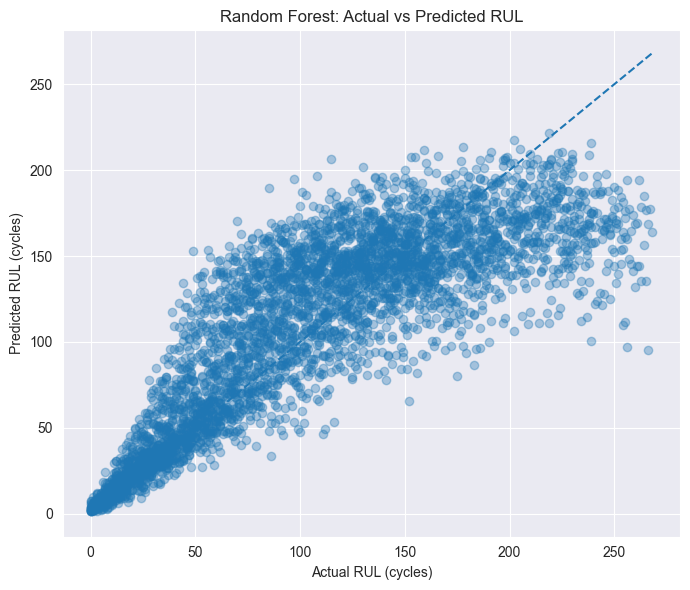

Mean error: 2.75
Median absolute error: 18.65
90th percentile absolute error: 60.61


In [11]:

# Calculate prediction errors
results = pd.DataFrame({
    "actual_RUL": y_val,
    "predicted_RUL": rf_pred
})

results["error"] = (
    results["predicted_RUL"] - results["actual_RUL"]
)

# Plot actual versus predicted RUL
plt.figure(figsize=(7, 6))
plt.scatter(
    results["actual_RUL"],
    results["predicted_RUL"],
    alpha=0.35
)

# Perfect-prediction reference line
min_value = min(
    results["actual_RUL"].min(),
    results["predicted_RUL"].min()
)
max_value = max(
    results["actual_RUL"].max(),
    results["predicted_RUL"].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual RUL (cycles)")
plt.ylabel("Predicted RUL (cycles)")
plt.title("Random Forest: Actual vs Predicted RUL")
plt.tight_layout()
plt.show()

# Summarize errors
print("Mean error:", round(results["error"].mean(), 2))
print("Median absolute error:", round(results["error"].abs().median(), 2))
print("90th percentile absolute error:",
      round(results["error"].abs().quantile(0.90), 2))

In [12]:

# Group predictions by actual remaining useful life
results["RUL_group"] = pd.cut(
    results["actual_RUL"],
    bins=[-1, 25, 50, 75, 100, float("inf")],
    labels=["0–25", "26–50", "51–75", "76–100", "100+"]
)

# Calculate metrics for each group
error_summary = results.groupby(
    "RUL_group",
    observed=False
).apply(
    lambda group: pd.Series({
        "count": len(group),
        "MAE": group["error"].abs().mean(),
        "Mean error": group["error"].mean()
    })
).round(2)

print(error_summary)

            count    MAE  Mean error
RUL_group                           
0–25        520.0   5.31        3.90
26–50       500.0  16.02       12.30
51–75       500.0  28.09       22.71
76–100      500.0  33.41       26.54
100+       2050.0  31.13      -10.55


C:\Users\Hp\AppData\Local\Temp\ipykernel_6896\677558753.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ).apply(


In [13]:

# Group predictions by actual RUL
results["RUL_group"] = pd.cut(
    results["actual_RUL"],
    bins=[-1, 25, 50, 75, 100, float("inf")],
    labels=["0–25", "26–50", "51–75", "76–100", "100+"]
)

# Calculate error metrics for each group
error_summary = results.groupby(
    "RUL_group",
    observed=False
).apply(
    lambda group: pd.Series({
        "count": len(group),
        "MAE": group["error"].abs().mean(),
        "Mean error": group["error"].mean()
    })
).round(2)

print(error_summary)

            count    MAE  Mean error
RUL_group                           
0–25        520.0   5.31        3.90
26–50       500.0  16.02       12.30
51–75       500.0  28.09       22.71
76–100      500.0  33.41       26.54
100+       2050.0  31.13      -10.55


C:\Users\Hp\AppData\Local\Temp\ipykernel_6896\2863082176.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ).apply(


In [14]:

# Compare actual and predicted RUL by actual RUL group
range_summary = results.groupby(
    "RUL_group",
    observed=False
).agg(
    actual_mean=("actual_RUL", "mean"),
    predicted_mean=("predicted_RUL", "mean"),
    MAE=("error", lambda x: x.abs().mean()),
    mean_error=("error", "mean"),
    count=("error", "size")
).round(2)

print(range_summary)

           actual_mean  predicted_mean    MAE  mean_error  count
RUL_group                                                       
0–25             12.50           16.40   5.31        3.90    520
26–50            38.00           50.30  16.02       12.30    500
51–75            63.00           85.71  28.09       22.71    500
76–100           88.00          114.54  33.41       26.54    500
100+            160.17          149.61  31.13      -10.55   2050


### Error Analysis by RUL Range

Validation errors varied substantially across remaining useful life (RUL) ranges. The model achieved its lowest MAE for engines with 0–25 cycles of RUL (5.31 cycles). MAE increased to 33.41 cycles in the 76–100 range.

Mean prediction error was positive for RUL values up to 100 cycles, indicating systematic overestimation in these groups. For RUL above 100 cycles, mean error was −10.55 cycles, indicating average underestimation.

These results reveal a range-dependent prediction bias that is not captured by a single overall MAE or R² score. Further experiments will investigate whether hyperparameter tuning improves accuracy and reduces this bias.
